In [13]:
from pathlib import Path
import json, platform, math
import jax
import jax.numpy as jnp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

jax.config.update('jax_enable_x64', True)
ROOT = Path.cwd() / 'bayesian_causal_outputs'
FIG = ROOT / 'figures'; REPORT = ROOT / 'reports'; DATA = ROOT / 'data'; SAMPLES = ROOT / 'posterior_samples'
for p in (ROOT, FIG, REPORT, DATA, SAMPLES): p.mkdir(parents=True, exist_ok=True)
SEED = 20261029
print('JAX', jax.__version__, 'backend', jax.default_backend())

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=165, bbox_inches='tight'); plt.show(); plt.close()

def rmse(y,p): return float(jnp.sqrt(jnp.mean((jnp.asarray(y)-jnp.asarray(p))**2)))
def coverage(lo,hi,truth): return float(jnp.mean((jnp.asarray(truth)>=jnp.asarray(lo)) & (jnp.asarray(truth)<=jnp.asarray(hi))))
def qinterval(draws, axis=0): return jnp.quantile(draws, jnp.array([0.025, 0.975]), axis=axis)


JAX 0.12.0.1 backend cpu


## Causal Data

Generate the data using the same structural equations as the first experiment.

$$
\begin{aligned}
U &\sim \mathcal N(\mu_e,1),\\
X &= 0.8U+\sigma_X\epsilon_X,\\
Y &= 2X+1.5U+0.5XU+\epsilon_Y,
\end{aligned}
\qquad \epsilon_X,\epsilon_Y\overset{\mathrm{iid}}{\sim}\mathcal N(0,1).
$$

For an intervention, set $X=x$ and keep $U$ and $\epsilon_Y$ fixed.

$$
Y(x)=2x+1.5U+0.5xU+\epsilon_Y.
$$

The true effect of changing speed from 0 to 1 is

$$
Y(1)-Y(0)=2+0.5U,\qquad \mathrm{ATE}_e=2+0.5\mu_e.
$$

Use $\mu_A=0$ and $\mu_B=2$, giving theoretical ATEs of 2 and 3.


In [2]:
def generate_scm(key, n, mu=0.0, sigma_x=1.0):
    ku,kx,ky = jax.random.split(key,3)
    u = mu+jax.random.normal(ku,(n,))
    ex = jax.random.normal(kx,(n,)); ey=jax.random.normal(ky,(n,))
    x = 0.8*u+sigma_x*ex
    def potential(xval): return 2*xval + 1.5*u + 0.5*xval*u + ey
    y=potential(x); y0=potential(jnp.zeros_like(x)); y1=potential(jnp.ones_like(x))
    return {'U':u,'X':x,'Y':y,'Y0':y0,'Y1':y1,'ITE':y1-y0, 'mu':mu}

keys=jax.random.split(jax.random.PRNGKey(SEED), 4)
TRAIN=generate_scm(keys[0], 1200,mu=0)
TEST_A=generate_scm(keys[1], 1000,mu=0)
TEST_B=generate_scm(keys[2], 1000,mu=2)
TEST_C=generate_scm(keys[3], 1000,mu=0,sigma_x=0.1)
for name, ds in [('train_A',TRAIN),('test_A',TEST_A),('test_B',TEST_B),('test_poor_overlap',TEST_C)]:
    pd.DataFrame({k:jax.device_get(v) for k,v in ds.items() if k!='mu'}).to_csv(DATA/f'{name}_oracle.csv',index=False)
    pd.DataFrame({k:jax.device_get(ds[k]) for k in ('U','X','Y')}).to_csv(DATA/f'{name}_observed.csv',index=False)
print('Theoretical ATE A=2.0, B=3.0. Empirical oracle A=',float(jnp.mean(TEST_A['ITE'])), 'B=',float(jnp.mean(TEST_B['ITE'])))
assert jnp.allclose(TRAIN['ITE'],2+0.5*TRAIN['U'])


Theoretical ATE A=2.0, B=3.0. Empirical oracle A= 2.001551917471966 B= 2.9686515080341684


## Bayesian Models

Fit three Gaussian regression models with different inputs.

$$
\begin{aligned}
\text{Speed only:}\quad &Y=\beta_0+\beta_X X+\eta,\\
\text{Adjusted:}\quad &Y=\beta_0+\beta_X X+\beta_U U+\eta,\\
\text{Interaction:}\quad &Y=\beta_0+\beta_X X+\beta_U U+\beta_{XU}XU+\eta.
\end{aligned}
$$

Use $\eta\sim\mathcal N(0,\sigma^2)$ and a normal-inverse-gamma prior.

$$
\boldsymbol\beta\mid\sigma^2\sim\mathcal N(\mathbf 0,\,100\sigma^2 I),
\qquad \sigma^2\sim\operatorname{InvGamma}(2,1).
$$

Calculate the conjugate posterior directly, then draw regression coefficients and noise variances.

The speed-only model leaves out workload. The interaction model includes the $XU$ term from the generator.


In [3]:
def design(ds, kind, x_override=None):
    x=ds['X'] if x_override is None else jnp.broadcast_to(jnp.asarray(x_override,dtype=jnp.float64),ds['X'].shape)
    u=ds['U']; one=jnp.ones_like(x)
    if kind=='speed_only': return jnp.stack([one,x],axis=1)
    if kind=='adjusted_additive': return jnp.stack([one,x,u],axis=1)
    if kind=='adjusted_interaction': return jnp.stack([one,x,u,x*u],axis=1)
    raise ValueError(kind)

def fit_bayes(ds,kind):
    X=design(ds,kind); y=ds['Y']; n,p=X.shape
    P0=jnp.eye(p)/100.; Pn=P0+X.T@X
    Vn=jnp.linalg.inv(Pn)
    bn=jnp.linalg.solve(Pn,X.T@y)
    an=2.+n/2
    dn=1.+0.5*(y@y-bn@(Pn@bn))
    assert float(dn)>0, 'Posterior scale must be positive'
    return {'kind':kind,'bn':bn,'Vn':Vn,'an':an,'dn':dn,'n':n}

def posterior_draws(fit,key,draws=2500):
    k1,k2=jax.random.split(key)
    # Gamma(shape=a, rate=d) is precision 1/sigma^2
    precision=jax.random.gamma(k1,fit['an'],shape=(draws,))/fit['dn']
    L=jnp.linalg.cholesky(fit['Vn'])
    z=jax.random.normal(k2,(draws,len(fit['bn'])))
    betas=fit['bn'][None,:]+(z@L.T)/jnp.sqrt(precision[:,None])
    return betas,1/precision

KINDS=['speed_only','adjusted_additive','adjusted_interaction']
fits={k:fit_bayes(TRAIN,k) for k in KINDS}
posterior={}
for idx,k in enumerate(KINDS):
    posterior[k]=posterior_draws(fits[k],jax.random.PRNGKey(SEED+101+idx))
    beta,s2=posterior[k]
    pd.DataFrame(jax.device_get(beta),columns=[f'b{i}' for i in range(beta.shape[1])]).assign(sigma2=jax.device_get(s2)).to_csv(SAMPLES/f'{k}_draws.csv',index=False)
    print(k,'posterior mean coefficients:',jnp.round(jnp.mean(beta,axis=0),3))


speed_only posterior mean coefficients: [0.355 2.741]
adjusted_additive posterior mean coefficients: [0.375 1.993 1.627]
adjusted_interaction posterior mean coefficients: [0.002 1.985 1.524 0.484]


adjusted_interaction posterior mean coefficients: [0.002 1.985 1.524 0.484]


## Causal Effects

Use posterior coefficient draws to estimate the effect of changing $X$ from 0 to 1.

$$
\begin{aligned}
\widehat\tau_{\mathrm{speed}}&=\beta_X,\\
\widehat\tau_{\mathrm{adjusted}}&=\beta_X,\\
\widehat\tau_{\mathrm{interaction}}(u)&=\beta_X+\beta_{XU}u.
\end{aligned}
$$

Average the individual effects over the workload values in each test population.

$$
\widehat{\mathrm{ATE}}_e=\frac1{n_e}\sum_{i=1}^{n_e}\widehat\tau(U_i).
$$

The speed-only coefficient is a naive comparison, not an identified causal effect.

Use posterior quantiles for the 95% credible intervals.


In [4]:
def causal_draws(kind, beta, ds):
    difference=design(ds,kind,x_override=1.)-design(ds,kind,x_override=0.)
    return beta@difference.T  # posterior draws x units

def mean_predict(kind,beta,ds): return design(ds,kind)@jnp.mean(beta,axis=0)

rows=[]; evals={}
for env,ds in [('A',TEST_A),('B_mean_shift',TEST_B),('poor_overlap',TEST_C)]:
    for kind in KINDS:
        beta,s2=posterior[kind]
        effects=causal_draws(kind,beta,ds)
        ate_draws=jnp.mean(effects,axis=1)
        lo,hi=qinterval(ate_draws)
        true_ate=float(jnp.mean(ds['ITE']))
        pred=mean_predict(kind,beta,ds)
        mean_ite=jnp.mean(effects,axis=0)
        row=dict(environment=env,model=kind,rmse=rmse(ds['Y'],pred),true_ate=true_ate,
                 theoretical_ate=3. if env=='B_mean_shift' else 2.,
                 ate_est=float(jnp.mean(ate_draws)),ate_low=float(lo),ate_high=float(hi),
                 ate_abs_error=abs(float(jnp.mean(ate_draws))-true_ate),
                 ite_rmse=rmse(ds['ITE'],mean_ite),
                 interval_contains_ate=int(float(lo)<=true_ate<=float(hi)))
        rows.append(row); evals[(env,kind)]={'ate':ate_draws,'ite':effects}
results=pd.DataFrame(rows)
results.to_csv(REPORT/'model_comparison.csv',index=False)
print(results.round(3).to_string(index=False))


 environment                model  rmse  true_ate  theoretical_ate  ate_est  ate_low  ate_high  ate_abs_error  ite_rmse  interval_contains_ate
           A           speed_only 1.719     2.002              2.0    2.741    2.666     2.819          0.740     0.897                      0
           A    adjusted_additive 1.301     2.002              2.0    1.993    1.923     2.062          0.008     0.507                      1
           A adjusted_interaction 0.998     2.002              2.0    1.987    1.933     2.041          0.015     0.022                      1
B_mean_shift           speed_only 4.310     2.969              3.0    2.741    2.666     2.819          0.227     0.555                      0
B_mean_shift    adjusted_additive 2.476     2.969              3.0    1.993    1.923     2.062          0.975     1.099                      0
B_mean_shift adjusted_interaction 1.001     2.969              3.0    2.922    2.839     3.006          0.047     0.050                      1

## Model Comparison

Compare predictions with the observed energy values.

$$
\mathrm{RMSE}=\sqrt{\frac1n\sum_{i=1}^{n}(Y_i-\widehat Y_i)^2}.
$$

Compare the estimated ATE with the oracle treatment effect from the generator.

$$
\mathrm{ATE\ error}=\left|\widehat{\mathrm{ATE}}-\mathrm{ATE}_{\mathrm{oracle}}\right|.
$$

Plot posterior ATE distributions, CATE bands, and intervention-response curves for the different environments.


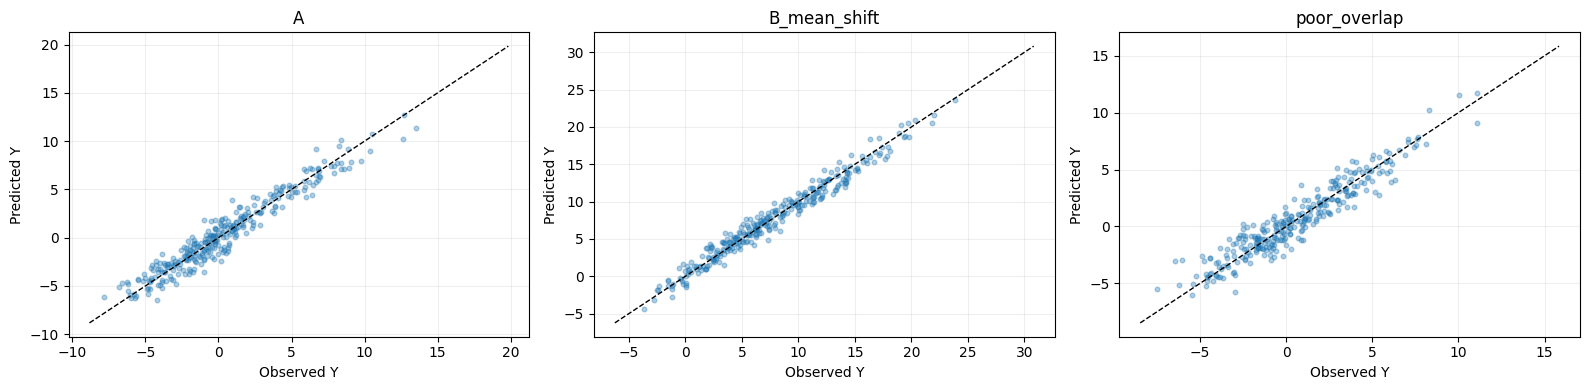

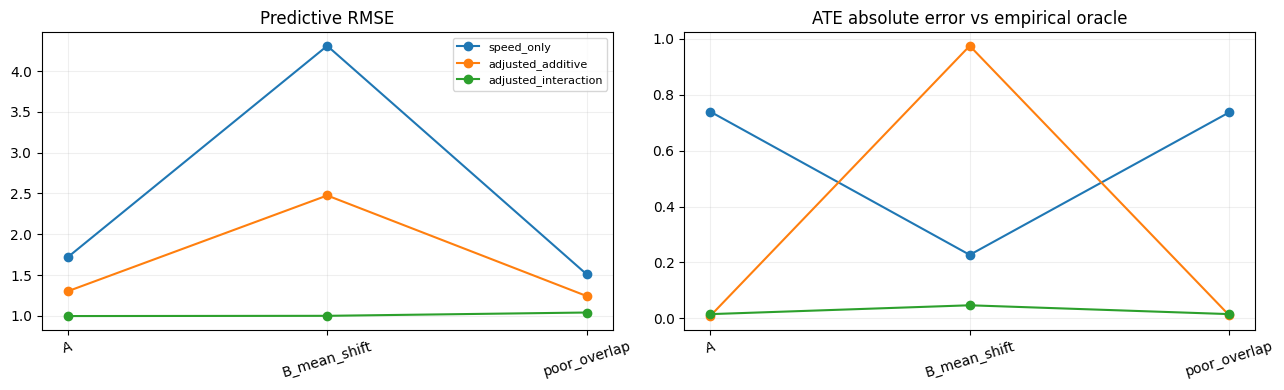

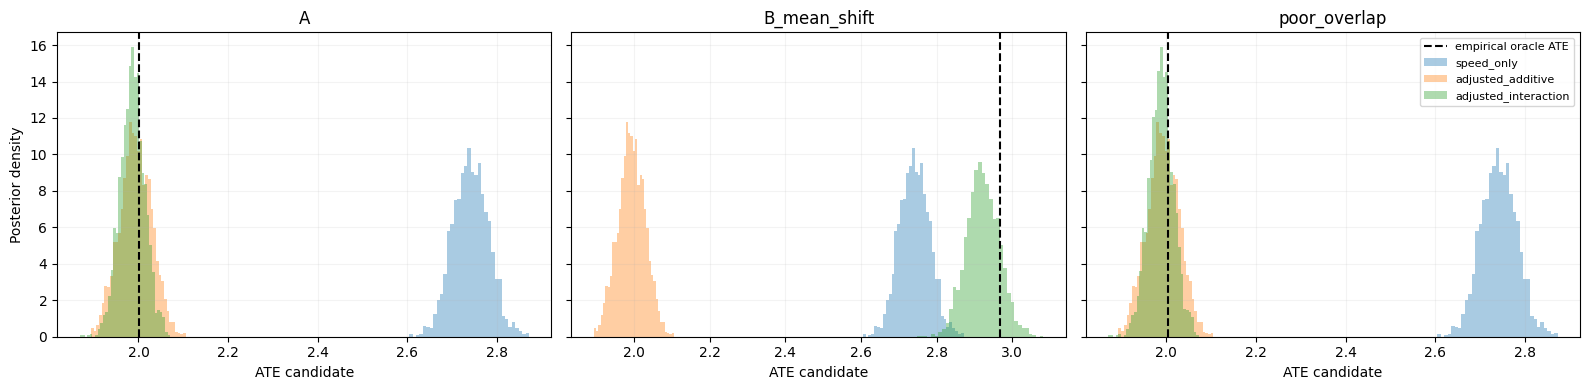

In [5]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,(env,ds) in zip(axes,[('A',TEST_A),('B_mean_shift',TEST_B),('poor_overlap',TEST_C)]):
    ax.scatter(jax.device_get(ds['Y'])[:300],jax.device_get(mean_predict('adjusted_interaction',posterior['adjusted_interaction'][0],ds))[:300],alpha=.35,s=11)
    lim=[float(jnp.min(ds['Y']))-1,float(jnp.max(ds['Y']))+1]
    ax.plot(lim,lim,'k--',lw=1);ax.set_title(env);ax.set_xlabel('Observed Y');ax.set_ylabel('Predicted Y');ax.grid(alpha=.2)
savefig('01_predictions_by_environment.png')

fig,axes=plt.subplots(1,2,figsize=(13,4))
for k in KINDS:
    sub=results[results.model==k]
    axes[0].plot(sub.environment,sub.rmse,'o-',label=k)
    axes[1].plot(sub.environment,sub.ate_abs_error,'o-',label=k)
axes[0].set_title('Predictive RMSE');axes[1].set_title('ATE absolute error vs empirical oracle')
for ax in axes: ax.tick_params(axis='x',rotation=17);ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
savefig('02_prediction_vs_causal_error.png')

fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
for ax,env in zip(axes,['A','B_mean_shift','poor_overlap']):
    ds={'A':TEST_A,'B_mean_shift':TEST_B,'poor_overlap':TEST_C}[env]
    ax.axvline(float(jnp.mean(ds['ITE'])),color='black',linestyle='--',label='empirical oracle ATE')
    for k in KINDS:
        v=jax.device_get(evals[(env,k)]['ate']);ax.hist(v,bins=35,density=True,alpha=.38,label=k)
    ax.set_title(env);ax.set_xlabel('ATE candidate');ax.grid(alpha=.15)
axes[0].set_ylabel('Posterior density');axes[-1].legend(fontsize=8)
savefig('03_ate_posterior_by_environment.png')


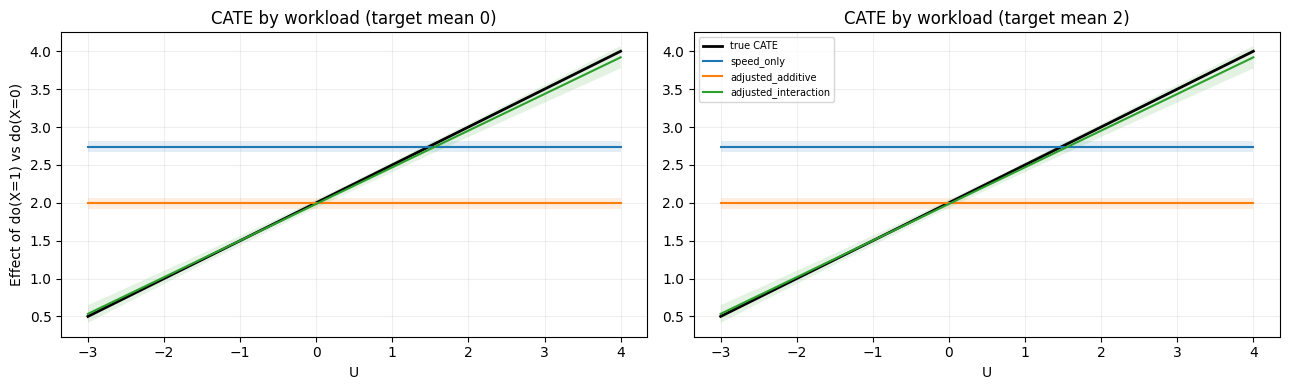

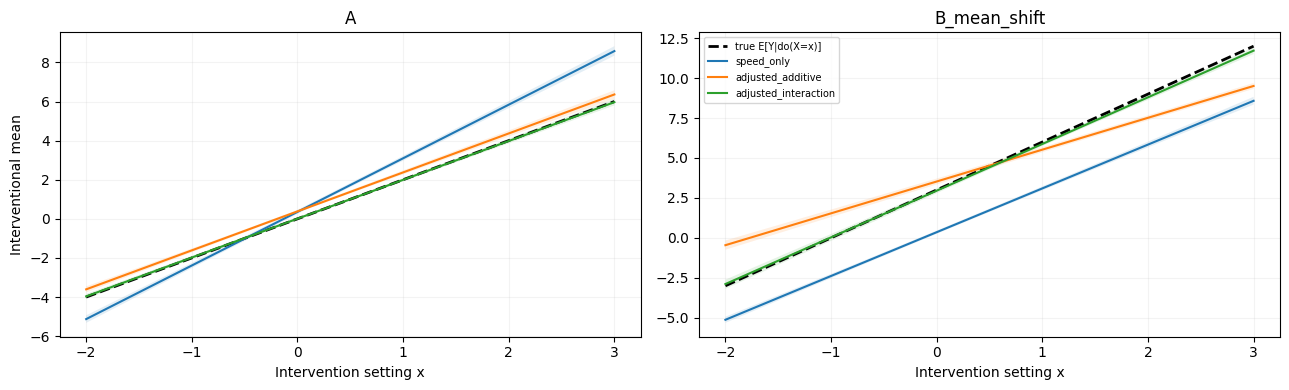

In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
u_grid=jnp.linspace(-3,4,90)
for ax,env_mu in zip(axes,[0.,2.]):
    oracle=2+0.5*u_grid
    ax.plot(u_grid,oracle,'k-',lw=2,label='true CATE')
    for k in KINDS:
        b=posterior[k][0]; fake={'X':jnp.zeros_like(u_grid),'U':u_grid}
        ef=causal_draws(k,b,fake)
        low,high=qinterval(ef,axis=0)
        ax.plot(u_grid,jnp.mean(ef,axis=0),label=k)
        ax.fill_between(u_grid,low,high,alpha=.13)
    ax.set_title(f'CATE by workload (target mean {env_mu:g})');ax.set_xlabel('U');ax.grid(alpha=.2)
axes[0].set_ylabel('Effect of do(X=1) vs do(X=0)');axes[-1].legend(fontsize=7)
savefig('04_cate_posterior_bands.png')

fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,(env,ds) in zip(axes,[('A',TEST_A),('B_mean_shift',TEST_B)]):
    xx=jnp.linspace(-2,3,60)
    true=2*xx+(1.5+0.5*xx)*(0. if env=='A' else 2.)
    ax.plot(xx,true,'k--',lw=2,label='true E[Y|do(X=x)]')
    for k in KINDS:
        betas=posterior[k][0]
        xlist=[]
        for x in xx:
            xlist.append(jnp.mean(design(ds,k,x_override=x)@betas.T,axis=0))
        means=jnp.stack(xlist,axis=1)
        lo,hi=qinterval(means,axis=0)
        ax.plot(xx,jnp.mean(means,axis=0),label=k)
        ax.fill_between(xx,lo,hi,alpha=.12)
    ax.set_title(env);ax.set_xlabel('Intervention setting x');ax.grid(alpha=.15)
axes[0].set_ylabel('Interventional mean');axes[1].legend(fontsize=7)
savefig('05_intervention_response_bands.png')


## Predictive Checks

Generate a new energy value for each posterior draw.

$$
Y_{\mathrm{new}}^{(s)}=\mathbf x^{\mathsf T}\boldsymbol\beta^{(s)}+\epsilon^{(s)},
\qquad \epsilon^{(s)}\sim\mathcal N(0,\sigma_{(s)}^2).
$$

The predictive interval includes both coefficient uncertainty and observation noise.

Compare the resulting 95% intervals with the test observations.


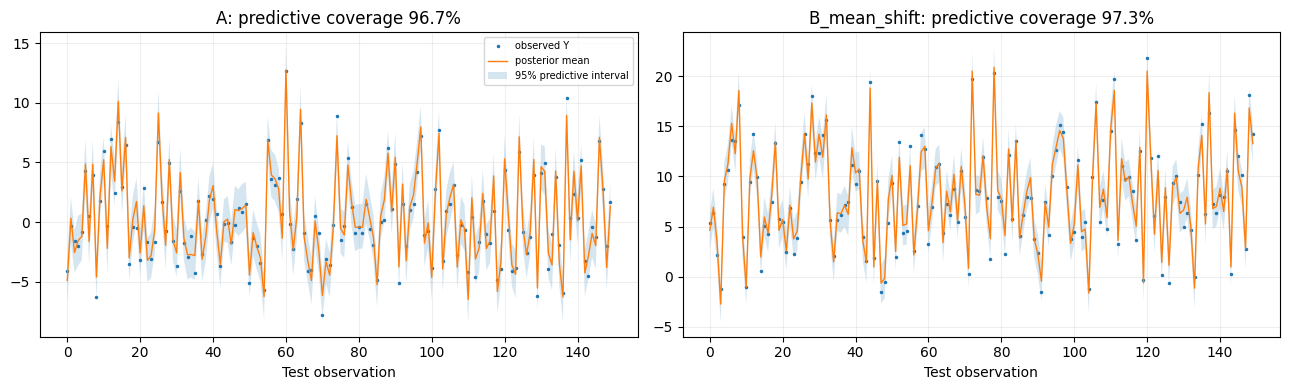

In [7]:
post_key=jax.random.PRNGKey(SEED+300)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,(env,ds) in zip(axes,[('A',TEST_A),('B_mean_shift',TEST_B)]):
    idx=jnp.arange(150)
    b,s2=posterior['adjusted_interaction']; b=b[:800];s2=s2[:800]
    mat=design(ds,'adjusted_interaction')[idx]
    mu=b@mat.T
    eps=jax.random.normal(jax.random.fold_in(post_key,0 if env=='A' else 1),mu.shape)
    replicated=mu+jnp.sqrt(s2)[:,None]*eps
    low,hi=qinterval(replicated,axis=0)
    y=ds['Y'][idx]
    cov=coverage(low,hi,y)
    ax.plot(jax.device_get(y),'.',markersize=3,label='observed Y')
    ax.plot(jax.device_get(jnp.mean(mu,axis=0)),lw=1,label='posterior mean')
    ax.fill_between(jnp.arange(len(idx)),low,hi,alpha=.18,label='95% predictive interval')
    ax.set_title(f'{env}: predictive coverage {cov:.1%}');ax.set_xlabel('Test observation');ax.grid(alpha=.2)
axes[0].legend(fontsize=7)
savefig('06_posterior_predictive_intervals.png')


## Interval Coverage

Repeat the analysis with 24 independent training datasets.

For each run, check whether the 95% ATE interval contains the theoretical population ATE of 2.

$$
\widehat{\mathrm{coverage}}=\frac1R\sum_{r=1}^{R}
\mathbb{1}\!\left\{L_r\leq 2\leq H_r\right\},\qquad R=24.
$$

Save coverage rates and average interval widths for the three models.


               model  coverage  mean_width  mean_ate
   adjusted_additive     0.875       0.216     1.987
adjusted_interaction     0.958       0.174     2.001
          speed_only     0.000       0.233     2.712


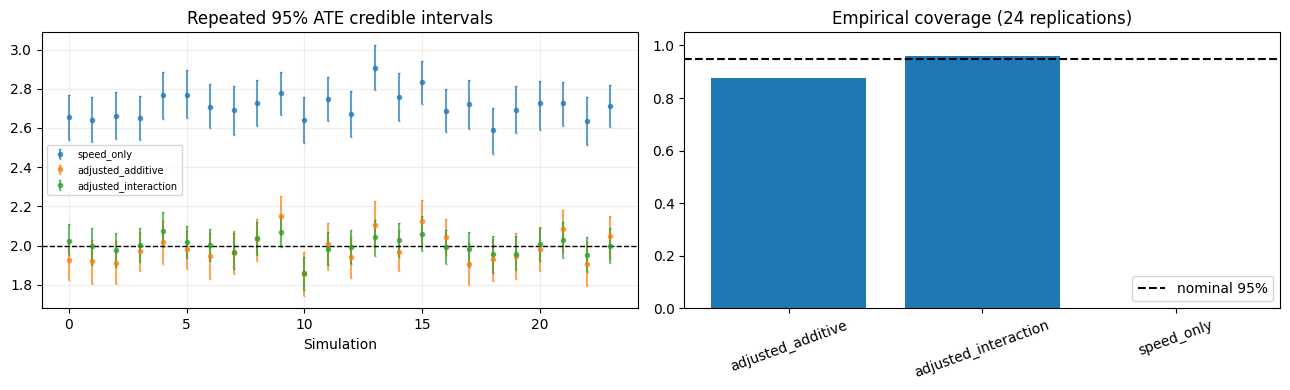

In [8]:
REPS=24
calib=[]
for i in range(REPS):
    training=generate_scm(jax.random.PRNGKey(SEED+1000+i),500,mu=0.)
    for kidx,k in enumerate(KINDS):
        fit=fit_bayes(training,k)
        beta,_=posterior_draws(fit,jax.random.PRNGKey(SEED+20000+i*5+kidx),draws=600)
        # target average U=0 exactly; for the interaction specification ATE is beta_X
        if k in ('speed_only','adjusted_additive','adjusted_interaction'):
            ate=beta[:,1]
        low,hi=qinterval(ate)
        calib.append({'replicate':i,'model':k,'ate_est':float(jnp.mean(ate)),
                      'low':float(low),'high':float(hi),'contains_true':bool(float(low)<=2<=float(hi)),
                      'interval_width':float(hi-low)})
cal=pd.DataFrame(calib);cal.to_csv(REPORT/'repeated_simulation_calibration.csv',index=False)
cal_summary=cal.groupby('model').agg(coverage=('contains_true','mean'),mean_width=('interval_width','mean'),mean_ate=('ate_est','mean')).reset_index()
cal_summary.to_csv(REPORT/'calibration_summary.csv',index=False)
print(cal_summary.round(3).to_string(index=False))
fig,axes=plt.subplots(1,2,figsize=(13,4))
for k in KINDS:
    sub=cal[cal.model==k].reset_index(drop=True)
    axes[0].errorbar(sub.replicate,sub.ate_est,yerr=[sub.ate_est-sub.low,sub.high-sub.ate_est],fmt='o',ms=3,capsize=1,label=k,alpha=.7)
axes[0].axhline(2,color='black',ls='--',lw=1);axes[0].set_title('Repeated 95% ATE credible intervals');axes[0].set_xlabel('Simulation');axes[0].grid(alpha=.2)
axes[1].bar(cal_summary.model,cal_summary.coverage);axes[1].axhline(.95,color='black',ls='--',label='nominal 95%')
axes[1].set_ylim(0,1.05);axes[1].set_title('Empirical coverage (24 replications)');axes[1].tick_params(axis='x',rotation=20);axes[1].legend()
axes[0].legend(fontsize=7)
savefig('07_repeated_interval_coverage.png')


## Hidden Confounding

Compare the speed-only posterior with the models adjusted for workload.

The omitted workload leaves the backdoor path open:

$$
X\leftarrow U\rightarrow Y.
$$

The identified intervention mean uses workload adjustment:

$$
\mathbb E[Y\mid do(X=x)]
=\int\mathbb E[Y\mid X=x,U=u]p(u)\,du.
$$

Plot ATE posterior distributions alongside the known causal effects.

Look at bias and interval width together.


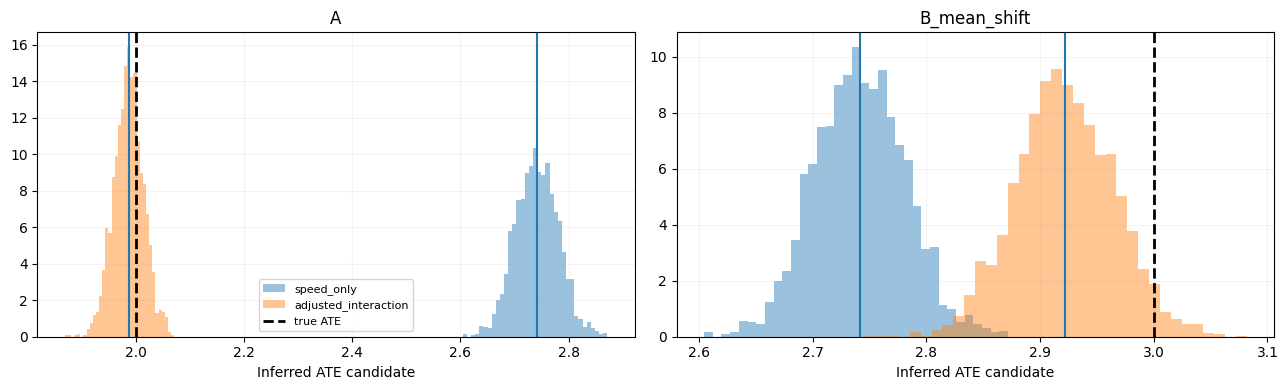

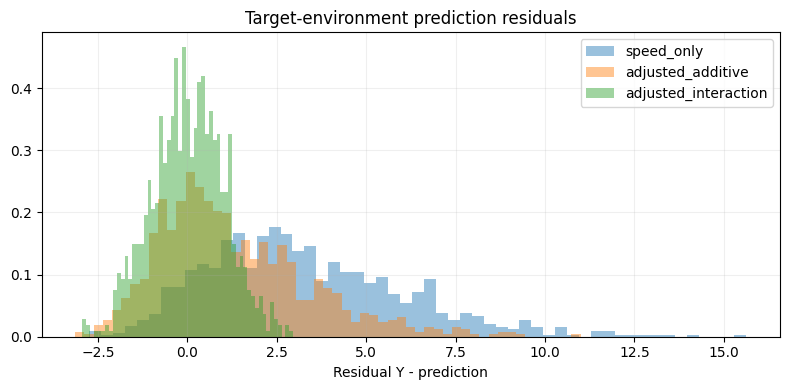

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,env in zip(axes,['A','B_mean_shift']):
    for k in ['speed_only','adjusted_interaction']:
        vals=jax.device_get(evals[(env,k)]['ate'])
        ax.hist(vals,bins=35,density=True,alpha=.45,label=k)
        ax.axvline(float(jnp.mean(vals)),lw=1.5)
    ax.axvline(2 if env=='A' else 3,color='black',lw=2,ls='--',label='true ATE')
    ax.set_title(env);ax.set_xlabel('Inferred ATE candidate');ax.grid(alpha=.15)
axes[0].legend(fontsize=8)
savefig('08_false_causal_certainty.png')

fig,ax=plt.subplots(figsize=(8,4))
for k in KINDS:
    residual=TEST_B['Y']-mean_predict(k,posterior[k][0],TEST_B)
    ax.hist(jax.device_get(residual),bins=55,alpha=.45,density=True,label=k)
ax.set_title('Target-environment prediction residuals');ax.set_xlabel('Residual Y - prediction');ax.legend();ax.grid(alpha=.2)
savefig('09_target_residual_distributions.png')


## NUTS Check

The main analysis samples directly from the conjugate Bayesian posterior.

NumPyro NUTS provides a separate posterior sampling check using

$$
Y_i\mid\boldsymbol\beta,\sigma\sim
\mathcal N(\mathbf x_i^{\mathsf T}\boldsymbol\beta,\sigma^2).
$$

Set `RUN_OPTIONAL_NUTS = True` after installing NumPyro to run this part.

The optional NUTS priors differ from the conjugate prior used above.


In [15]:
RUN_OPTIONAL_NUTS = False
if RUN_OPTIONAL_NUTS:
    try:
        import numpyro
        import numpyro.distributions as dist
        from numpyro.infer import MCMC, NUTS
        def model(X,y=None):
            beta=numpyro.sample('beta',dist.Normal(jnp.zeros(X.shape[1]),jnp.ones(X.shape[1])*10).to_event(1))
            sigma=numpyro.sample('sigma',dist.HalfNormal(2.))
            numpyro.sample('obs',dist.Normal(X@beta,sigma),obs=y)
        X=design(TRAIN,'adjusted_interaction')
        mcmc=MCMC(NUTS(model),num_warmup=350,num_samples=650,num_chains=1,progress_bar=False)
        mcmc.run(jax.random.PRNGKey(SEED+999),X,TRAIN['Y'])
        smp=mcmc.get_samples()
        print('NUTS beta posterior mean',jnp.mean(smp['beta'],axis=0))
        pd.DataFrame(jax.device_get(smp['beta']),columns=['intercept','X','U','XU']).to_csv(SAMPLES/'optional_nuts_beta.csv',index=False)
    except ImportError:
        print('NumPyro not installed; optional NUTS skipped. Install using %pip install numpyro')
else:
    print('NumPyro NUTS disabled; exact Bayesian conjugate posterior was used above.')


NumPyro NUTS disabled; exact Bayesian conjugate posterior was used above.


## Results

Save the posterior summaries, calibration tables, plots, and experiment settings.

Compare predictive RMSE, ATE error, and 95% interval coverage.

Use the causal graph to distinguish adjusted causal effects from the naive speed-only estimates.

The coverage experiment includes 24 runs.


In [14]:
summary={
    'research_question':'Bayesian predictive accuracy versus reliability of causal-effect uncertainty',
    'seed':SEED,'jax_version':jax.__version__,'backend':jax.default_backend(),
    'models':KINDS,'num_posterior_samples':2500,'num_calibration_repetitions':REPS,
    'training_n':len(TRAIN['X']),'test_n':len(TEST_A['X']),
    'scm':{'X':'0.8*U+eps_x','Y':'2*X+1.5*U+0.5*X*U+eps_y'},
    'outputs':{'figures':len(list(FIG.glob('*.png'))),'reports':len(list(REPORT.glob('*.csv')))},
    'key_caveat':'Speed-only model does not identify causal effects due to unobserved workload confounding'
}
(ROOT/'experiment_metadata.json').write_text(json.dumps(summary,indent=2))
(ROOT/'README.md').write_text(readme)
print('\nMain ATE comparison (target A):')
print(results[results.environment=='A'][['model','ate_est','ate_low','ate_high','theoretical_ate','ate_abs_error']].round(3).to_string(index=False))



Main ATE comparison (target A):
               model  ate_est  ate_low  ate_high  theoretical_ate  ate_abs_error
          speed_only    2.741    2.666     2.819              2.0          0.740
   adjusted_additive    1.993    1.923     2.062              2.0          0.008
adjusted_interaction    1.987    1.933     2.041              2.0          0.015
